In [25]:
%matplotlib inline
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import pandas as pd
import scipy
from scipy import stats
from scipy.optimize import curve_fit
import h5py
import pickle

In [26]:
# File paths
path_qcd = "uwphys434/Sample_pt_250_500-20261104T215933Z-1-001/Sample_pt_250_500/qcd_100000_pt_250_500.h5"
path_higgs = "uwphys434/Sample_pt_250_500-20261104T215933Z-1-001/Sample_pt_250_500/higgs_100000_pt_250_500.h5"

# Function to inspect HDF5 file structure
def print_h5_structure(filepath):
    with h5py.File(filepath, 'r') as f:
        print(f"Structure for {filepath}:")
        def print_keys(name, obj):
            if isinstance(obj, h5py.Dataset):
                print(f"  Dataset: {name} | Shape: {obj.shape} | Type: {obj.dtype}")
        f.visititems(print_keys)
        print()

print_h5_structure(path_qcd)
print_h5_structure(path_higgs)

Structure for uwphys434/Sample_pt_250_500-20261104T215933Z-1-001/Sample_pt_250_500/qcd_100000_pt_250_500.h5:
  Dataset: qcd_100000_pt_250_500 | Shape: (100000, 14) | Type: float64

Structure for uwphys434/Sample_pt_250_500-20261104T215933Z-1-001/Sample_pt_250_500/higgs_100000_pt_250_500.h5:
  Dataset: higgs_100000_pt_250_500 | Shape: (100000, 14) | Type: float64



Mean value of each of the 14 columns:
QCD:   [ 4.4571e+02 -0.0000e+00 -0.0000e+00  9.7740e+01  9.0000e-02  0.0000e+00
  5.2100e+00  0.0000e+00  9.1000e-01  5.9000e-01  4.8000e-01  6.5000e-01
  8.1000e-01  3.2000e-01]
Higgs: [ 4.4739e+02 -0.0000e+00  0.0000e+00  1.1489e+02  1.3000e-01  0.0000e+00
  1.9700e+00  0.0000e+00  9.0000e-01  3.1000e-01  2.3000e-01  3.5000e-01
  7.6000e-01  5.3000e-01]


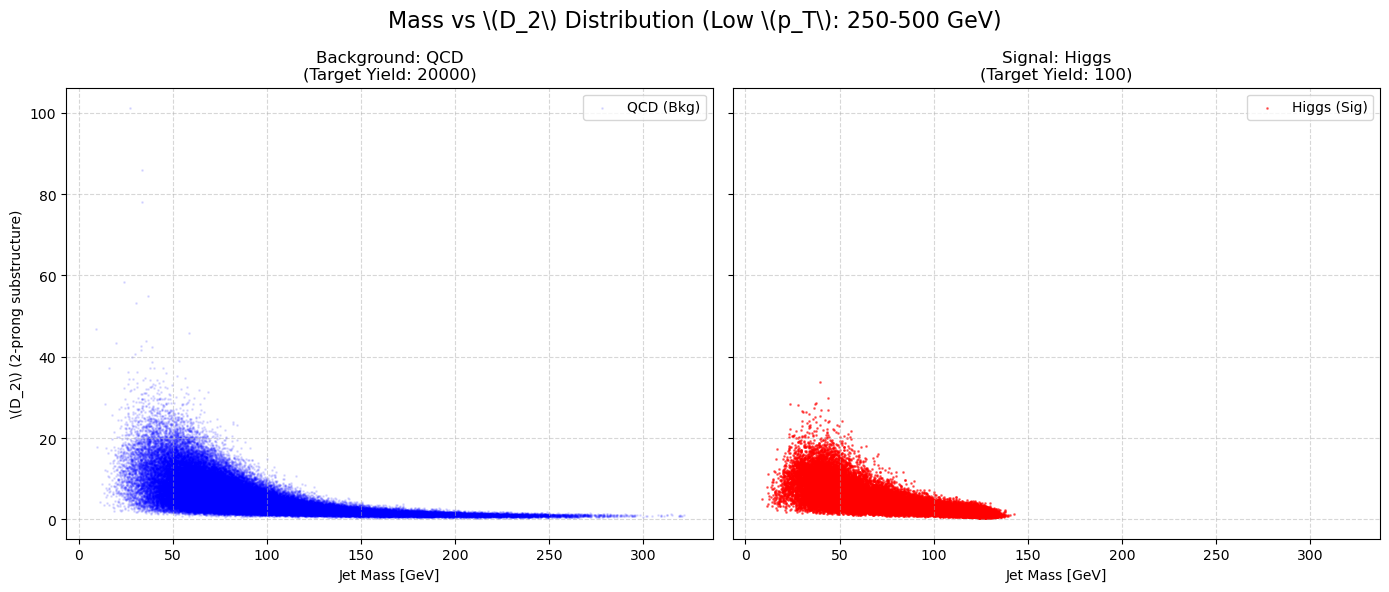

In [1]:
import h5py
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 1. Define the paths
folder = "uwphys434/Sample_pt_250_500-20261104T215933Z-1-001/Sample_pt_250_500"
path_qcd = f"{folder}/qcd_100000_pt_250_500.h5"
path_higgs = f"{folder}/higgs_100000_pt_250_500.h5"

# 2. Load the data
with h5py.File(path_qcd, 'r') as f:
    qcd_array = f['qcd_100000_pt_250_500'][:] 
with h5py.File(path_higgs, 'r') as f:
    higgs_array = f['higgs_100000_pt_250_500'][:] 

# --- looking at the first row to find mass and d2 ---
# printing the mean of each column to help figure out which is which
print("Mean value of each of the 14 columns:")
print(f"QCD:   {np.mean(qcd_array, axis=0).round(2)}")
print(f"Higgs: {np.mean(higgs_array, axis=0).round(2)}")



mass_idx = 3  
d2_idx = 6  

df_qcd = pd.DataFrame({'mass': qcd_array[:, mass_idx], 'd2': qcd_array[:, d2_idx]})
df_higgs = pd.DataFrame({'mass': higgs_array[:, mass_idx], 'd2': higgs_array[:, d2_idx]})

# 3. Apply weights
target_yield_sig = 100
target_yield_bkg = 20000
weight_sig = target_yield_sig / len(df_higgs)
weight_bkg = target_yield_bkg / len(df_qcd)

# 4. Make the scatter plot
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6), sharex=True, sharey=True)

# Plot Background (QCD)
ax1.scatter(df_qcd['mass'], df_qcd['d2'], s=1, alpha=0.1, color='blue', label='QCD (Bkg)')
ax1.set_title(f'Background: QCD\n(Target Yield: {target_yield_bkg})')
ax1.set_xlabel('Jet Mass [GeV]')
ax1.set_ylabel(r'\(D_2\) (2-prong substructure)')
ax1.legend()
ax1.grid(True, linestyle='--', alpha=0.5)

# Plot Signal (Higgs)
ax2.scatter(df_higgs['mass'], df_higgs['d2'], s=1, alpha=0.5, color='red', label='Higgs (Sig)')
ax2.set_title(f'Signal: Higgs\n(Target Yield: {target_yield_sig})')
ax2.set_xlabel('Jet Mass [GeV]')
ax2.legend()
ax2.grid(True, linestyle='--', alpha=0.5)

plt.suptitle(r'Mass vs \(D_2\) Distribution (Low \(p_T\): 250-500 GeV)', fontsize=16)
plt.tight_layout()
plt.show()

# Lab 5 - Final Project Proposal - LHC Data
For my final project, I will analyze the sample LHC data provided in lab to investigate the detection of the Higgs boson against the QCD background. The data is divided into two folders based on transverse momentum ranges: pt_250_500 and pt_1000_1200. I plan to first explore the data for patterns and differences between the Higgs signal and QCD background, including how these change between the two transverse momentum ranges. From there, I will use statistical methods to investigate how well the Higgs signal can be distinguished from the background and calculate its statistical significance.